Сотниченко Артем Валентинович 

КН23002б


Тема:Банківський скоринг

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Виносимо налаштування в конфіг як просили в методичці
DATA_PATH = "Churn_Modelling.csv"
TARGET = 'Exited'
RANDOM_STATE = 42
TEST_SIZE = 0.2

# вантажимо датасет
df = pd.read_csv(DATA_PATH)
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Завантажили датасет. Бачимо що є колонки які явно не потрібні для моделі

In [16]:
# викидаємо зайве
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# загальна інфа
print(df.info())
print("\nПропуски:\n", df.isna().sum())
print("\nДублікати:", df.duplicated().sum())

# дивимось базову статистику
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB
None

Пропуски:
 CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited            

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


пропусків і дублікатів немає, постатистиці видно, що середній вік клієнтів в районі 39 років а середній баланс на рахунку 76 тис

Exited
0    7963
1    2037
Name: count, dtype: int64


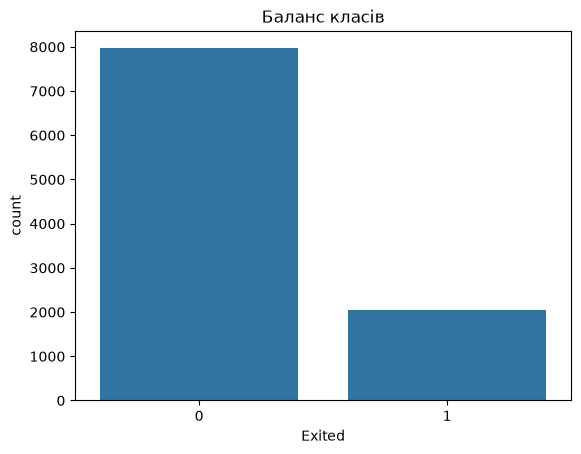

In [ ]:
# перевіряємо баланс класів чи є дисбаланс
print(df[TARGET].value_counts())

sns.countplot(x=TARGET, data=df)
plt.title("Баланс класів")
plt.show()

Є дисбаланс класів 8000 клієнтів залишились (0) і тільки 2000 пішли (1) Це може бути проблемою для майбутньої моделі

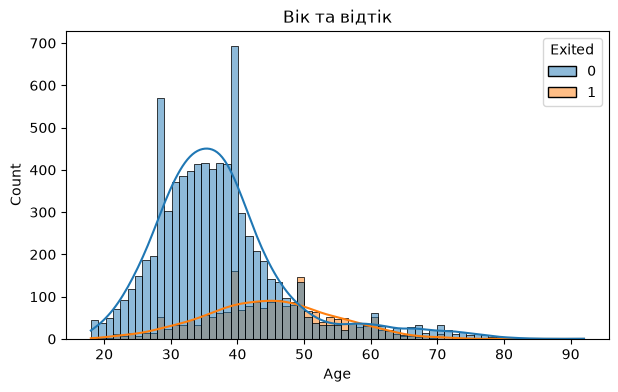

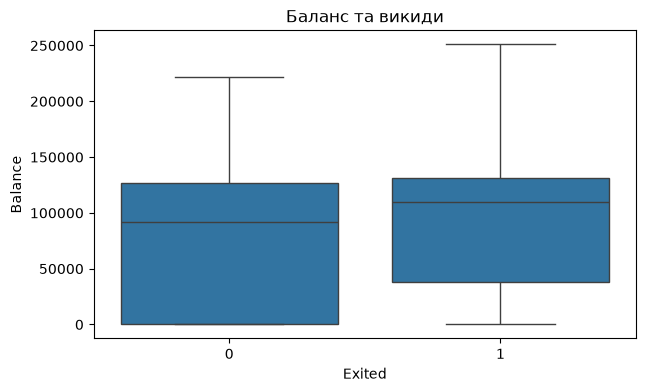

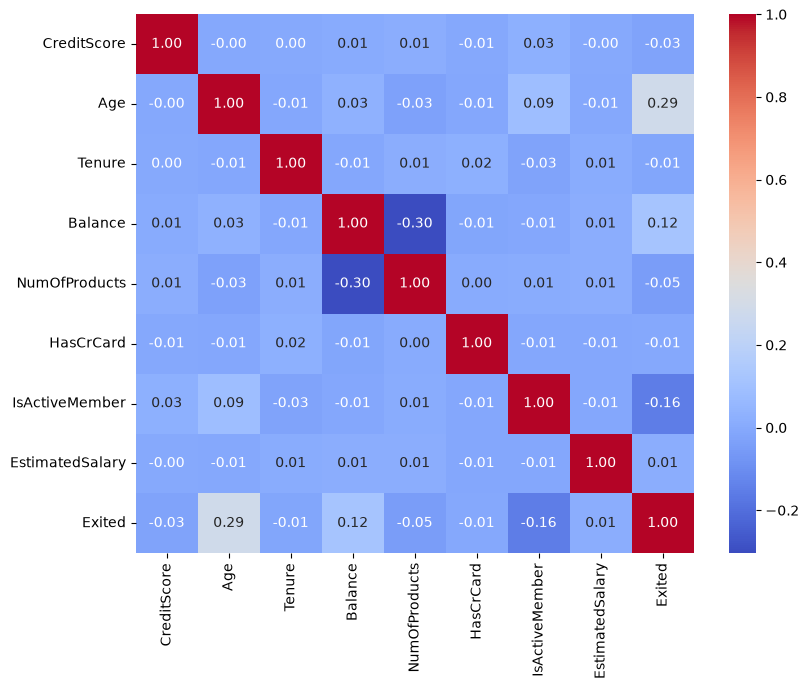

In [ ]:
# робимо графіки щоб глянути на фічі
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='Age', hue=TARGET, kde=True)
plt.title("Вік та відтік")
plt.show()

# шукаємо викиди
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x=TARGET, y='Balance')
plt.title("Баланс та викиди")
plt.show()

# матриця кореляції
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

По віку чітко видно старіші люди (40-50 років) частіше закривають рахунки викидів у балансі немає (є багато нулів, але для банку це нормальна ситуація) Сильної кореляції між ознаками теж нема тому нічого додатково видаляти не треба

In [ ]:
# текстові дані (країна, стать) в числа 
df = pd.get_dummies(df, drop_first=True)

# розбиваємо на X та y
X = df.drop(columns=[TARGET])
y = df[TARGET]

from sklearn.model_selection import train_test_split

# ділимо на трейн і тест. stratify обовязково щоб зберегти пропорцію 80/20 в обох вибірках
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(X_train.shape, X_test.shape)

(8000, 11) (2000, 11)


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# масштабуємо дані 
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# зберігаємо результати для другої лаби
pd.DataFrame(X_train_scaled, columns=X.columns).to_csv("X_train.csv", index=False)
pd.DataFrame(X_test_scaled, columns=X.columns).to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

### Підсумкові висновки

**1. Датасет і задача:**
Використовуємо датасет Churn_Modelling. Задача — класифікація: передбачити, чи закриє клієнт рахунок в банку (target = Exited) 

**2. Проблеми з даними:**
Датасет норм пропусків та дублікатів не було Єдине, що довелося прибрати це айдішніки номери рядків та прізвища, бо для алгоритму вони не несуть ніякого сенсу

**3. Що зроблено (перетворення):**
- Видалили зайве
- Текстові колонки (країна, стать) перевели в нулі та одиниці через get_dummies
- Розбили дані на train та test (80 на 20)
- Відмасштабували числові ознаки через StandardScaler Скейлер навчався суто на трейні, тому data leakage немає

**4. Цікаві фічі:**
Графіки показали що найсильніше на відтік впливає вік клієнта Викидів, які б довелось видаляти, я не знайшов

**5. Баланс класів:**
Є сильний дисбаланс десь 80% на 20%

**6. Готовність:**
Дані почищені, закодовані, відскейлені і розбиті. Повністю готові для навчання моделі

**7. Ризики для k-NN (наступна лаба):**
Через дисбаланс класів алгоритм k-NN може просто передбачати для всіх клієнтів клас "0" (що вони залишаться). Тоді метрика Accuracy буде високою ~80%, але реально тих хто хоче піти модель не знайде. Доведеться дивитись на інші метрики типу F1-score або recall